# What Drives the Price of a Used Car?

**CRISP-DM analysis of 426,880 used-car listings, with recommendations for a used car dealership**

**Contents**
1. [Business Understanding](#1.-Business-Understanding)
2. [Data Understanding](#2.-Data-Understanding)
3. [Data Preparation](#3.-Data-Preparation)
4. [Exploratory Analysis of the Cleaned Data](#4.-Exploratory-Analysis-of-the-Cleaned-Data)
5. [Modeling](#5.-Modeling)
6. [Evaluation](#6.-Evaluation)
7. [Findings and Recommendations (Deployment)](#7.-Findings-and-Recommendations-(Deployment))

This notebook follows the CRISP-DM process: Business Understanding, Data Understanding, Data Preparation, Modeling, Evaluation, Deployment.

## 1. Business Understanding

**Business question.** A used car dealership wants to know *what consumers value in a used car*, so it can fine-tune the inventory it buys and stocks.

**Reframed as a data task.** This is a **supervised regression** problem. The target is the listing price (`price`, continuous). The predictors are vehicle attributes: age, mileage, condition, manufacturer, body type, fuel, drivetrain, transmission, cylinders and so on. We want a model that:

1. predicts price well enough to show that the attributes explain price (checked with held-out data and cross-validation), and
2. is **interpretable**, so that each coefficient can be read as "how much does this attribute move the price, holding the others constant?"

Because interpretability is a goal, we use regularized **linear models** (Linear Regression, Ridge, Lasso) and tune their regularization strength with grid search.

**Success measures.** (a) Cross-validated R² and (b) mean absolute error (MAE) in dollars on a held-out test set. See the metric rationale in Section 5.

**Caveat to keep in mind.** The data are *asking prices* from online listings, not final sale prices, and the model finds *associations*, not causes.

## 2. Data Understanding

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42

**Load the data and take a first look.** The file has one row per listing.

In [2]:
df_raw = pd.read_csv('data/vehicles.csv')
print(f'Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}')
df_raw.head()

Rows: 426,880   Columns: 18


,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


In [3]:
# Summary of the numeric columns (transposed so it fits on screen)
df_raw[['price', 'year', 'odometer']].describe(percentiles=[.01, .5, .99]).T.round(0)

,count,mean,std,min,1%,50%,99%,max
price,426880.0,75199.0,12182282.0,0.0,0.0,13950.0,66995.0,3.736929e+09
year,425675.0,2011.0,9.0,1900.0,1967.0,2013.0,2020.0,2.022000e+03
odometer,422480.0,98043.0,213882.0,0.0,2.0,85548.0,280000.0,1.000000e+07


**Observations.** The price column contains impossible values: a minimum of \$0 and a maximum in the billions, while the median is about \$14k. `year` and `odometer` also have extreme values. We quantify the problems below.

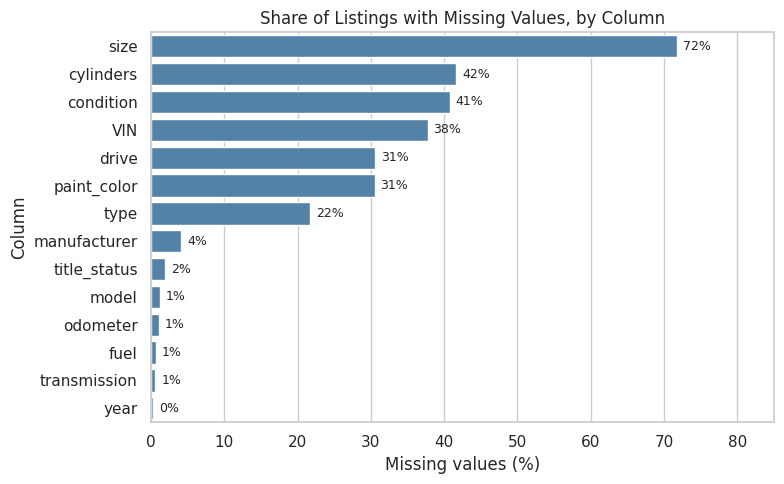

In [4]:
# Share of missing values per column
missing_pct = (df_raw.isnull().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=missing_pct.values, y=missing_pct.index, color='steelblue', ax=ax)
ax.set_title('Share of Listings with Missing Values, by Column')
ax.set_xlabel('Missing values (%)')
ax.set_ylabel('Column')
for i, v in enumerate(missing_pct.values):
    ax.text(v + 0.8, i, f'{v:.0f}%', va='center', fontsize=9)
ax.set_xlim(0, 85)
plt.tight_layout()
plt.show()

In [5]:
# Quantify the data quality problems we need to fix
n = len(df_raw)
quality = pd.Series({
    'Price = $0': (df_raw['price'] == 0).sum(),
    'Price between $1 and $999': df_raw['price'].between(1, 999).sum(),
    'Price above $100,000': (df_raw['price'] > 100_000).sum(),
    'Model year before 1995': (df_raw['year'] < 1995).sum(),
    'Odometer under 100 miles (placeholders)': (df_raw['odometer'] < 100).sum(),
    'Odometer above 400,000 miles': (df_raw['odometer'] > 400_000).sum(),
    'Duplicate listings (ignoring id)': df_raw.drop(columns='id').duplicated().sum(),
}, name='Rows affected').to_frame()
quality['% of data'] = (quality['Rows affected'] / n * 100).round(1)
quality

,Rows affected,% of data
Price = $0,32895,7.7
Price between $1 and $999,13420,3.1
"Price above $100,000",655,0.2
Model year before 1995,15896,3.7
Odometer under 100 miles (placeholders),6640,1.6
"Odometer above 400,000 miles",1702,0.4
Duplicate listings (ignoring id),56202,13.2


In [6]:
# Cardinality of the text columns: high-cardinality columns are impractical to one-hot encode
cat_cols_raw = df_raw.select_dtypes(exclude='number').columns
df_raw[cat_cols_raw].nunique().sort_values(ascending=False).to_frame('Unique values')

,Unique values
VIN,118246
model,29649
region,404
state,51
manufacturer,42
type,13
paint_color,12
cylinders,8
title_status,6
condition,6


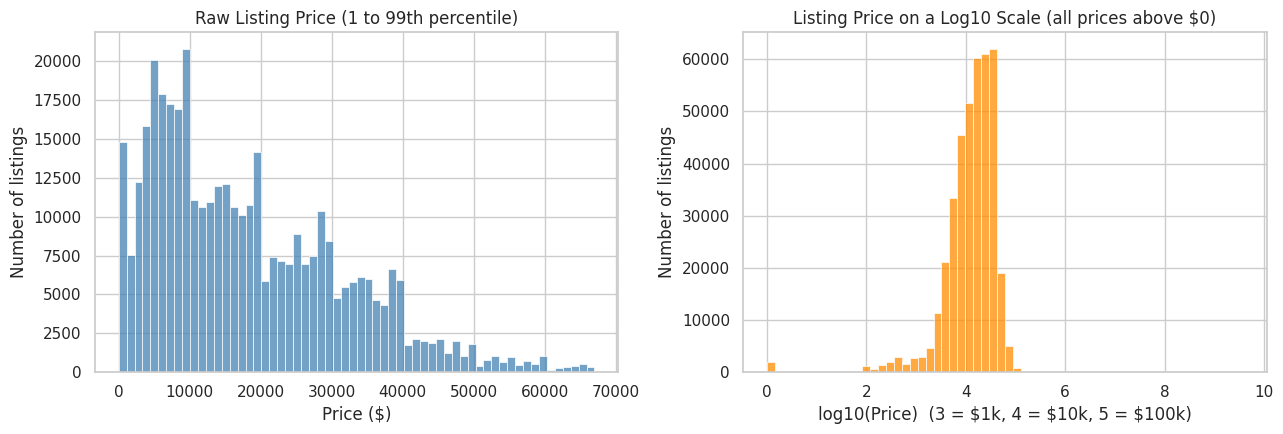

In [7]:
# Raw price distribution (clipped to the 99th percentile for visibility) vs. log-scale
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df_raw.loc[df_raw['price'].between(1, df_raw['price'].quantile(.99)), 'price'],
             bins=60, color='steelblue', ax=axes[0])
axes[0].set_title('Raw Listing Price (1 to 99th percentile)')
axes[0].set_xlabel('Price ($)')
axes[0].set_ylabel('Number of listings')

sns.histplot(np.log10(df_raw.loc[df_raw['price'] > 0, 'price']), bins=60, color='darkorange', ax=axes[1])
axes[1].set_title('Listing Price on a Log10 Scale (all prices above $0)')
axes[1].set_xlabel('log10(Price)  (3 = $1k, 4 = $10k, 5 = $100k)')
axes[1].set_ylabel('Number of listings')
plt.tight_layout()
plt.show()

**What we learned in Data Understanding**

- **Target problems:** About 8% of listings have a price of \$0, and a tail of listings above \$100k runs up to billions. These are placeholders or typos, not real prices.
- **Skew:** Price is strongly right-skewed. On a log scale it is much closer to symmetric, so modeling `log(price)` is appropriate. It also means effects are *multiplicative* (e.g. "10% lower"), which is how buyers think about price.
- **Missing data:** `size` (about 72%), `cylinders` and `condition` (about 41% each), `drive` and `paint_color` (about 31% each) are heavily missing. Filling these with the most common value (the mode) would invent information, so we keep "unknown" as its own category instead.
- **Duplicates:** About 13% of listings are exact duplicates once the listing `id` is ignored. These would give some cars extra weight.
- **High cardinality:** `model` (about 30k values), `region` (about 400) and `VIN` (an identifier) cannot be encoded usefully with a linear model, so they are excluded.

## 3. Data Preparation

In [8]:
# Cleaning pipeline with a row count after every step so the impact is visible
log = []
df = df_raw.copy()
log.append(('Raw data', len(df)))

# 1. Remove duplicate listings (same everything except the listing id)
df = df.drop_duplicates(subset=[c for c in df.columns if c != 'id'])
log.append(('Remove duplicate listings', len(df)))

# 2. Keep realistic prices: $1,000 to $100,000 (removes $0 placeholders, typos, exotic outliers)
df = df[df['price'].between(1_000, 100_000)]
log.append(('Keep prices $1k-$100k', len(df)))

# 3. Year and odometer are essential predictors, so rows missing them are dropped (< 2% of data)
df = df.dropna(subset=['year', 'odometer'])
log.append(('Drop rows missing year/odometer', len(df)))

# 4. Scope: mainstream used cars, model years 1995-2021, odometer 100 to 400,000 miles.
#    Odometer readings under 100 are placeholders (many listings show exactly 10 miles at a round-number
#    price), and only 18 listings have model year 2022, mostly with placeholder prices.
df = df[df['year'].between(1995, 2021) & df['odometer'].between(100, 400_000)]
log.append(('Model year 1995-2021, odometer 100-400k', len(df)))

pd.DataFrame(log, columns=['Step', 'Rows remaining']).assign(
    **{'% of raw': lambda t: (t['Rows remaining'] / len(df_raw) * 100).round(1)})

,Step,Rows remaining,% of raw
0,Raw data,426880,100.0
1,Remove duplicate listings,370678,86.8
2,Keep prices $1k-$100k,334451,78.3
3,Drop rows missing year/odometer,331911,77.8
4,"Model year 1995-2021, odometer 100-400k",313596,73.5


In [9]:
# Feature engineering
# Age is measured from model year 2021, the newest year kept (newest cars have age 0)
df['car_age'] = (2021 - df['year']).astype(int)

# Target: log of price, so coefficients can be read as percentage changes
df['log_price'] = np.log(df['price'])

# Missing categorical values become their own 'unknown' category rather than being guessed
categorical_features = ['manufacturer', 'condition', 'cylinders', 'fuel', 'title_status',
                        'transmission', 'drive', 'size', 'type', 'paint_color', 'state']
df[categorical_features] = df[categorical_features].fillna('unknown')

numeric_features = ['car_age', 'odometer']

# Columns dropped: id/VIN (identifiers), model/region (too many levels), year (replaced by car_age,
# which is perfectly collinear with it)
df = df.drop(columns=['id', 'VIN', 'model', 'region', 'year'])
print(f'Final modeling dataset: {df.shape[0]:,} rows x {df.shape[1]} columns')
df[numeric_features + ['price']].describe().T.round(1)

Final modeling dataset: 313,596 rows x 15 columns


,count,mean,std,min,25%,50%,75%,max
car_age,313596.0,8.5,5.6,0.0,4.0,7.0,12.0,26.0
odometer,313596.0,92945.5,63615.0,100.0,37647.0,86886.5,136290.5,400000.0
price,313596.0,19634.4,14213.6,1000.0,7995.0,16500.0,28590.0,100000.0


**Encoding and scaling.** All preprocessing sits inside a scikit-learn `Pipeline`, so scaling and encoding are learned **only from the training folds** (no data leakage).

- Numeric features (`car_age`, `odometer`) are standardized. Ridge and Lasso penalize coefficient size, so features must be on the same scale. We convert back to "per year" and "per 10,000 miles" when interpreting.
- Categorical features are one-hot encoded with an explicit **reference category** for each one (the most common or most neutral level). Each coefficient is then read as *"compared with the reference level"*.

In [10]:
# Reference (baseline) category for each categorical feature
reference = {'manufacturer': 'ford', 'condition': 'good', 'cylinders': '6 cylinders', 'fuel': 'gas',
             'title_status': 'clean', 'transmission': 'automatic', 'drive': 'fwd', 'size': 'unknown',
             'type': 'sedan', 'paint_color': 'white', 'state': 'ca'}

preprocess = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop=[reference[c] for c in categorical_features], handle_unknown='ignore'),
     categorical_features),
])

X = df[numeric_features + categorical_features]
y = df['log_price']

# 80/20 train-test split; the test set is untouched until the final evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape[0]:,} rows   Test: {X_test.shape[0]:,} rows')

Train: 250,876 rows   Test: 62,720 rows


## 4. Exploratory Analysis of the Cleaned Data

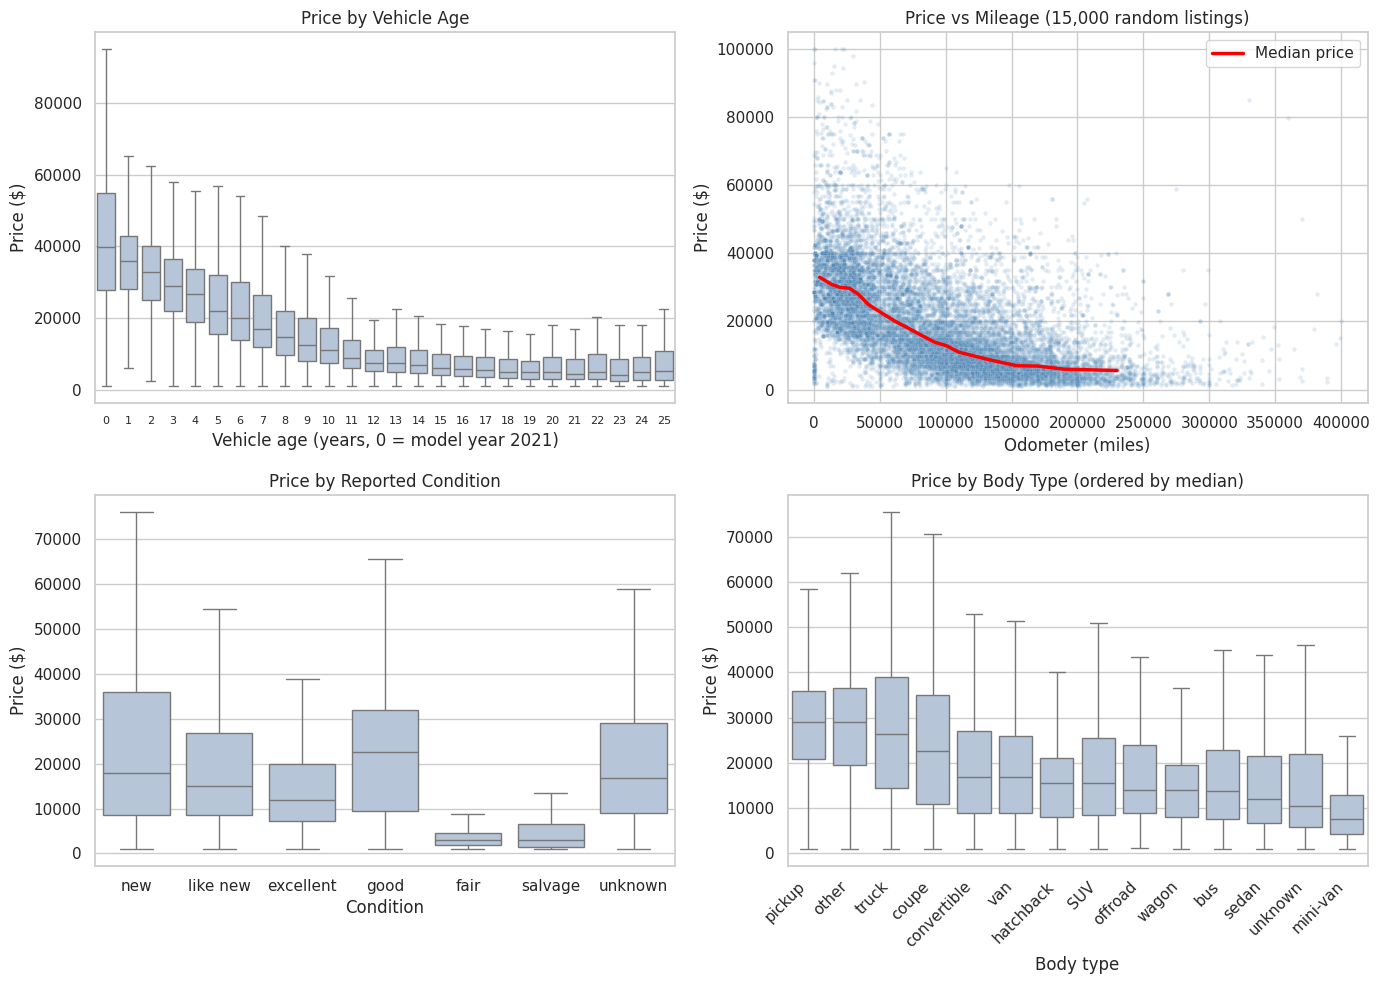

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) Price by age: distribution for each age (continuous predictor)
age_order = sorted(df['car_age'].unique())
sns.boxplot(data=df[df['car_age'] <= 25], x='car_age', y='price', color='lightsteelblue',
            showfliers=False, ax=axes[0, 0])
axes[0, 0].set_title('Price by Vehicle Age')
axes[0, 0].set_xlabel('Vehicle age (years, 0 = model year 2021)')
axes[0, 0].set_ylabel('Price ($)')
axes[0, 0].tick_params(axis='x', labelsize=8)

# (b) Price vs mileage on a random sample, with a smoothed trend line
sample = df.sample(15_000, random_state=RANDOM_STATE)
sns.scatterplot(data=sample, x='odometer', y='price', alpha=0.15, s=10, color='steelblue', ax=axes[0, 1])
# Trend line: median price within 20 equal-sized mileage bins
trend = df.groupby(pd.qcut(df['odometer'], 20), observed=True).agg(odometer=('odometer', 'median'),
                                                                     price=('price', 'median'))
axes[0, 1].plot(trend['odometer'], trend['price'], color='red', linewidth=2.5, label='Median price')
axes[0, 1].legend()
axes[0, 1].set_title('Price vs Mileage (15,000 random listings)')
axes[0, 1].set_xlabel('Odometer (miles)')
axes[0, 1].set_ylabel('Price ($)')

# (c) Price by condition, ordered from best to worst
cond_order = ['new', 'like new', 'excellent', 'good', 'fair', 'salvage', 'unknown']
sns.boxplot(data=df, x='condition', y='price', order=cond_order, color='lightsteelblue',
            showfliers=False, ax=axes[1, 0])
axes[1, 0].set_title('Price by Reported Condition')
axes[1, 0].set_xlabel('Condition')
axes[1, 0].set_ylabel('Price ($)')

# (d) Price by body type, ordered by median price
type_order = df.groupby('type')['price'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='type', y='price', order=type_order, color='lightsteelblue',
            showfliers=False, ax=axes[1, 1])
axes[1, 1].set_title('Price by Body Type (ordered by median)')
axes[1, 1].set_xlabel('Body type')
axes[1, 1].set_ylabel('Price ($)')
plt.setp(axes[1, 1].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

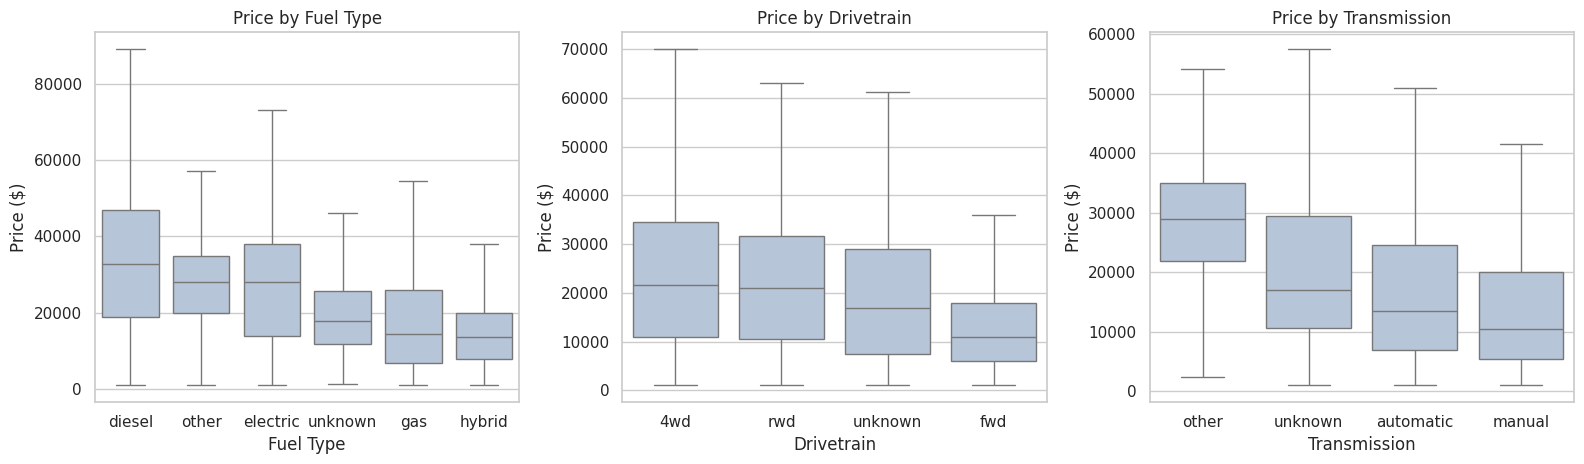

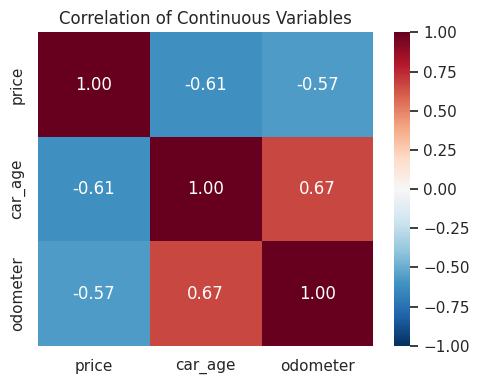

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, col, title in zip(axes, ['fuel', 'drive', 'transmission'],
                          ['Fuel Type', 'Drivetrain', 'Transmission']):
    order = df.groupby(col)['price'].median().sort_values(ascending=False).index
    sns.boxplot(data=df, x=col, y='price', order=order, color='lightsteelblue', showfliers=False, ax=ax)
    ax.set_title(f'Price by {title}')
    ax.set_xlabel(title)
    ax.set_ylabel('Price ($)')
plt.tight_layout()
plt.show()

# Correlation of the continuous variables; age and mileage move together
corr = df[['price', 'car_age', 'odometer']].corr()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation of Continuous Variables')
plt.tight_layout()
plt.show()

**What the exploration shows (descriptive, before any model)**

- Median price falls steadily with age and with mileage. The mileage relationship is clearly curved (steep at first, then flattening), which is another reason to use log price.
- `fair` and `salvage` cars sit far below the rest. Among the other condition labels the raw medians are *not* in the expected order (for example `good` is above `excellent`), because condition labels are mixed up with age and mileage: `excellent` cars tend to be older. The regression in Section 5 separates these effects.
- Pickups and trucks have the highest typical prices among the common body types, ahead of SUVs, while sedans and mini-vans are among the lowest. In raw prices, diesel and electric vehicles and 4WD / RWD vehicles sit above gas and FWD ones, although electric's premium is partly because electric cars in the data are newer. Manual cars actually show the *lowest* raw median price, mostly because they are older, so raw averages can mislead and the model below is needed to separate these effects.
- Age and mileage are strongly correlated with each other (see heatmap). A regression is needed to separate their effects, and this correlation is why coefficients should be read as "holding the other features constant".

## 5. Modeling

### Evaluation metrics and rationale

| Metric | Why we use it |
|---|---|
| **R² (cross-validated)**: primary metric for *model selection* | Share of the variation in log-price the model explains. It is unit-free, so it is easy to compare models and shows how much of price the listed attributes can account for. |
| **MAE in dollars**: primary metric for *business reporting* | The average size of the error, in dollars. Dealers can read it directly ("on average the estimate is off by about \$X"), and unlike RMSE it is not dominated by a few very expensive cars. |
| **RMSE on log-price**: secondary | Roughly the typical *percentage* error, and it penalizes large misses more than MAE. |

All models are fitted to `log(price)`. For dollar-based metrics, predictions are converted back with `exp()`.

In [13]:
# Baseline and candidate models, evaluated with 5-fold cross-validation on the training set only
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    'Baseline (predict mean)': DummyRegressor(),
    'Linear Regression': LinearRegression(),
    'Ridge (alpha=1)': Ridge(alpha=1.0),
    'Lasso (alpha=0.001)': Lasso(alpha=0.001, max_iter=5000),
}

rows = []
for name, estimator in candidates.items():
    pipe = Pipeline([('prep', preprocess), ('model', estimator)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=['r2', 'neg_mean_absolute_error'])
    rows.append({'Model': name,
                 'CV R2 (mean)': scores['test_r2'].mean(),
                 'CV R2 (std)': scores['test_r2'].std(),
                 'CV MAE (log-price)': -scores['test_neg_mean_absolute_error'].mean()})
cv_table = pd.DataFrame(rows).set_index('Model').round(4)
cv_table

,CV R2 (mean),CV R2 (std),CV MAE (log-price)
Model,,,
Baseline (predict mean),-0.0000,0.0000,0.6911
Linear Regression,0.7792,0.0033,0.2762
Ridge (alpha=1),0.7792,0.0033,0.2762
Lasso (alpha=0.001),0.7673,0.0030,0.2839


### Hyperparameter tuning with grid search

Ridge and Lasso both have one key hyperparameter, `alpha` (regularization strength). We search a grid of values with 5-fold cross-validation, scoring on R².

Ridge: best alpha = 1, best CV R2 = 0.7792


Lasso: best alpha = 1e-05, best CV R2 = 0.7792


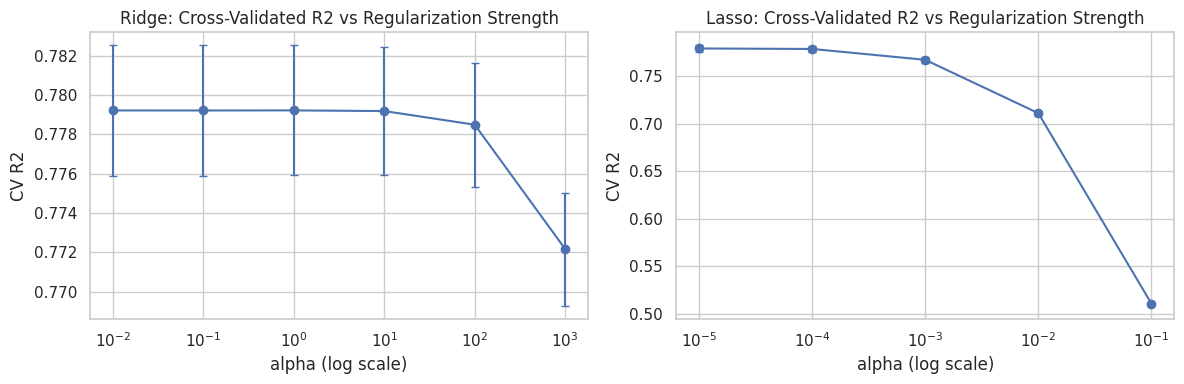

In [14]:
grid_specs = {
    'Ridge': (Ridge(), {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]}),
    'Lasso': (Lasso(max_iter=5000), {'model__alpha': [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]}),
}

searches = {}
for name, (estimator, grid) in grid_specs.items():
    pipe = Pipeline([('prep', preprocess), ('model', estimator)])
    searches[name] = GridSearchCV(pipe, grid, cv=cv, scoring='r2', n_jobs=1).fit(X_train, y_train)
    print(f"{name}: best alpha = {searches[name].best_params_['model__alpha']}, "
          f"best CV R2 = {searches[name].best_score_:.4f}")

# Visualize how CV R2 changes with alpha
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, gs) in zip(axes, searches.items()):
    res = pd.DataFrame(gs.cv_results_)
    ax.errorbar(res['param_model__alpha'].astype(float), res['mean_test_score'],
                yerr=res['std_test_score'], marker='o', capsize=3)
    ax.set_xscale('log')
    ax.set_title(f'{name}: Cross-Validated R2 vs Regularization Strength')
    ax.set_xlabel('alpha (log scale)')
    ax.set_ylabel('CV R2')
plt.tight_layout()
plt.show()

**Reading the grid search.** Ridge peaks at alpha = 1, and Lasso peaks at the *smallest* alpha tried (almost no penalty). With roughly 250,000 training rows and about 150 features, there is little overfitting for regularization to remove, so Linear Regression, Ridge and tuned Lasso all reach the same cross-validated R² (differences are far smaller than the fold-to-fold standard deviation). We therefore keep **Ridge**, whose small penalty keeps coefficients stable when features such as age and mileage are correlated, and use it for interpretation.

## 6. Evaluation

In [15]:
# Compare tuned models on the held-out test set (used once, after all tuning is done)
def evaluate(model, name):
    pred_log = model.predict(X_test)
    return {'Model': name,
            'Test R2 (log-price)': r2_score(y_test, pred_log),
            'RMSE (log-price)': np.sqrt(mean_squared_error(y_test, pred_log)),
            'MAE ($)': mean_absolute_error(np.exp(y_test), np.exp(pred_log)),
            'Median abs. % error': np.median(np.abs(np.exp(pred_log) / np.exp(y_test) - 1)) * 100}

baseline = Pipeline([('prep', preprocess), ('model', DummyRegressor())]).fit(X_train, y_train)
test_table = pd.DataFrame([evaluate(baseline, 'Baseline (predict mean)')] +
                          [evaluate(gs.best_estimator_, f'{n} (tuned)') for n, gs in searches.items()]
                          ).set_index('Model').round(3)
test_table

,Test R2 (log-price),RMSE (log-price),MAE ($),Median abs. % error
Model,,,,
Baseline (predict mean),-0.000,0.841,11222.622,53.650
Ridge (tuned),0.785,0.391,4741.778,19.844
Lasso (tuned),0.785,0.391,4740.166,19.820


Final model: Ridge, alpha = 1


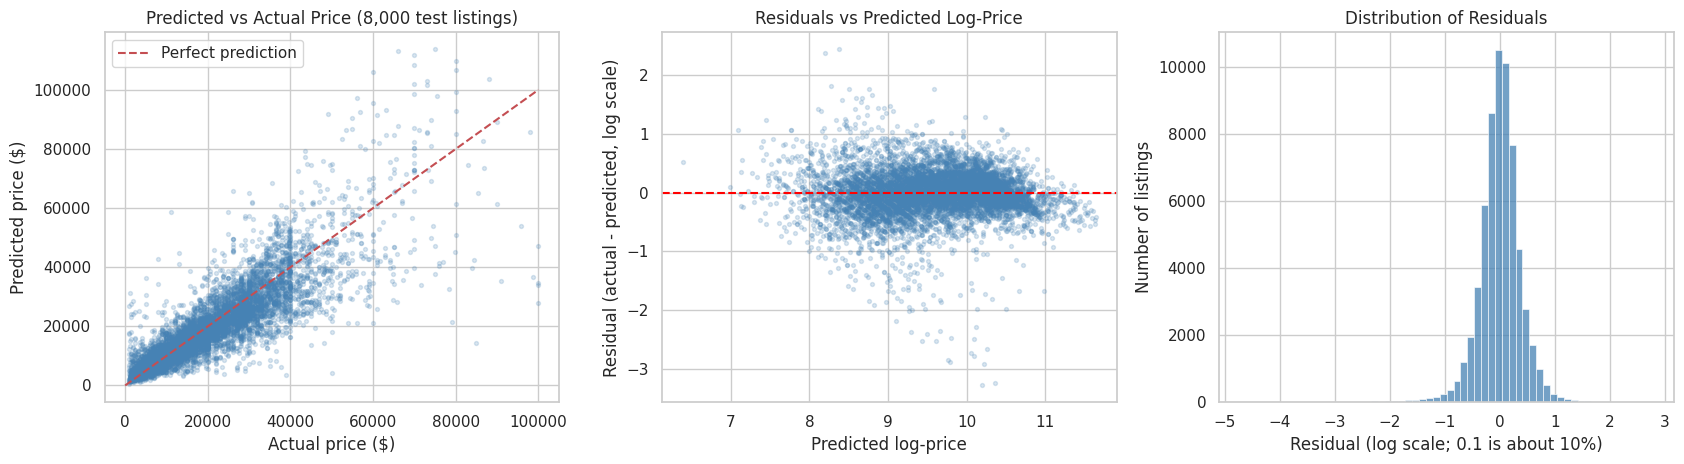

,listings,MAE_dollars,median_pct_error
band,,,
<$5k,7974,2338.9,41.6
$5-10k,12724,2100.3,20.3
$10-20k,16976,3260.2,17.0
$20-40k,20514,6271.2,17.4
$40-100k,4529,14983.6,25.3


In [16]:
# Final model: choose the best cross-validated model (ties go to Ridge, the more stable choice)
best_name = max(searches, key=lambda n: round(searches[n].best_score_, 3) + (n == 'Ridge') * 1e-6)
final_model = searches[best_name].best_estimator_
print(f'Final model: {best_name}, alpha = {searches[best_name].best_params_["model__alpha"]}')

pred_log = final_model.predict(X_test)
actual, pred = np.exp(y_test), np.exp(pred_log)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) Predicted vs actual
idx = np.random.RandomState(RANDOM_STATE).choice(len(actual), 8_000, replace=False)
axes[0].scatter(actual.values[idx], pred[idx], alpha=0.2, s=8, color='steelblue')
axes[0].plot([0, 100_000], [0, 100_000], 'r--', label='Perfect prediction')
axes[0].set_title('Predicted vs Actual Price (8,000 test listings)')
axes[0].set_xlabel('Actual price ($)')
axes[0].set_ylabel('Predicted price ($)')
axes[0].legend()

# (b) Residuals vs predicted (log scale): checks for systematic patterns
resid = y_test.values - pred_log
axes[1].scatter(pred_log[idx], resid[idx], alpha=0.2, s=8, color='steelblue')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residuals vs Predicted Log-Price')
axes[1].set_xlabel('Predicted log-price')
axes[1].set_ylabel('Residual (actual - predicted, log scale)')

# (c) Residual distribution
sns.histplot(resid, bins=60, color='steelblue', ax=axes[2])
axes[2].set_title('Distribution of Residuals')
axes[2].set_xlabel('Residual (log scale; 0.1 is about 10%)')
axes[2].set_ylabel('Number of listings')
plt.tight_layout()
plt.show()

# Error by price band
bands = pd.cut(actual, [0, 5_000, 10_000, 20_000, 40_000, 100_000],
               labels=['<$5k', '$5-10k', '$10-20k', '$20-40k', '$40-100k'])
err = pd.DataFrame({'band': bands, 'abs_err': np.abs(actual - pred), 'pct_err': np.abs(pred / actual - 1) * 100})
err.groupby('band', observed=True).agg(listings=('abs_err', 'size'), MAE_dollars=('abs_err', 'mean'),
                                       median_pct_error=('pct_err', 'median')).round(1)

### Interpreting the coefficients

The model predicts `log(price)`, so a coefficient *b* means that a one-unit change multiplies the price by *exp(b)*. We report that as a **percentage effect** = (exp(b) − 1) × 100.

- **Numeric features** were standardized, so we divide by the standard deviation to express them *per year of age* and *per 10,000 miles*.
- **Categorical features** are compared with their reference level (e.g. `condition` is compared with *good*, `type` with *sedan*, `fuel` with *gas*).
- Effects are **all else equal**, so the age effect already excludes the extra mileage older cars have.

,% change in price
Each extra year of age,-7.1
"Each extra 10,000 miles",-3.8


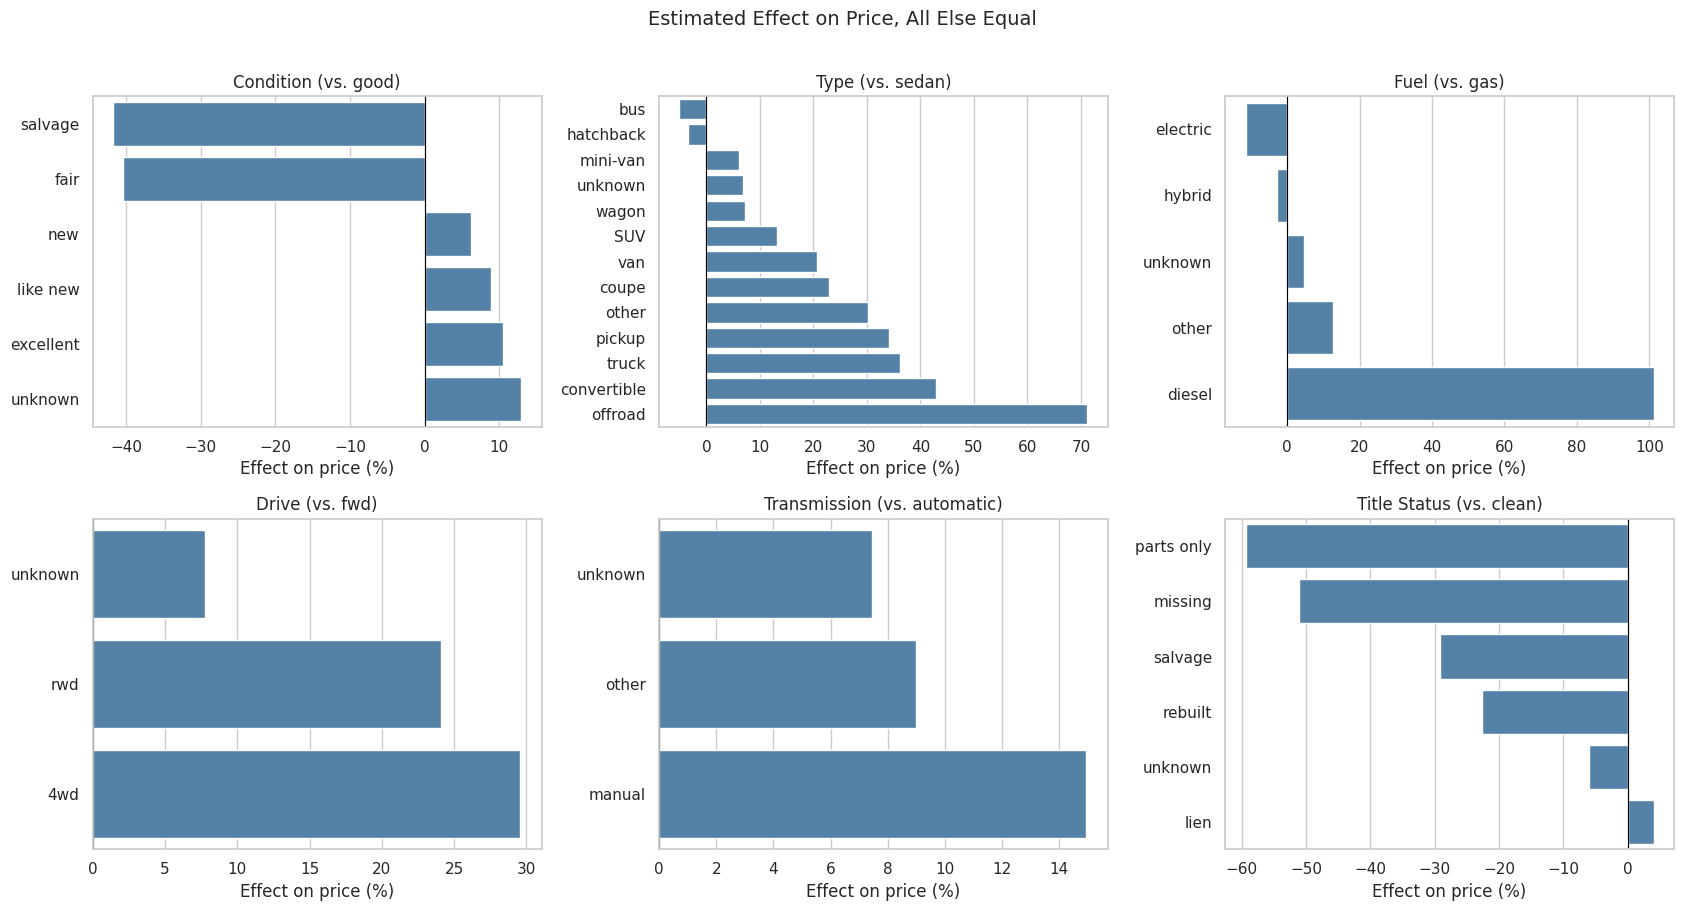

In [17]:
# Convert fitted coefficients into percentage effects on price
feature_names = final_model.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(final_model.named_steps['model'].coef_, index=feature_names)

# Numeric effects: undo standardization to get 'per year' and 'per 10,000 miles'
scaler = final_model.named_steps['prep'].named_transformers_['num']
per_unit = {'car_age': coefs['num__car_age'] / scaler.scale_[0],
            'odometer_10k': coefs['num__odometer'] / scaler.scale_[1] * 10_000}
numeric_effects = pd.Series({'Each extra year of age': (np.exp(per_unit['car_age']) - 1) * 100,
                             'Each extra 10,000 miles': (np.exp(per_unit['odometer_10k']) - 1) * 100},
                            name='% change in price').round(1)
display(numeric_effects.to_frame())

# Categorical effects
cat = coefs[coefs.index.str.startswith('cat__')].rename('coef').to_frame()
cat['group'] = [next(c for c in categorical_features if n.startswith(f'cat__{c}_')) for n in cat.index]
cat['level'] = [n.replace(f'cat__{g}_', '') for n, g in zip(cat.index, cat['group'])]
cat['pct_effect'] = (np.exp(cat['coef']) - 1) * 100

groups = ['condition', 'type', 'fuel', 'drive', 'transmission', 'title_status']
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, g in zip(axes.ravel(), groups):
    d = cat[cat['group'] == g].sort_values('pct_effect')
    sns.barplot(data=d, x='pct_effect', y='level', color='steelblue', ax=ax)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{g.replace("_", " ").title()} (vs. {reference[g]})')
    ax.set_xlabel('Effect on price (%)')
    ax.set_ylabel('')
plt.suptitle('Estimated Effect on Price, All Else Equal', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

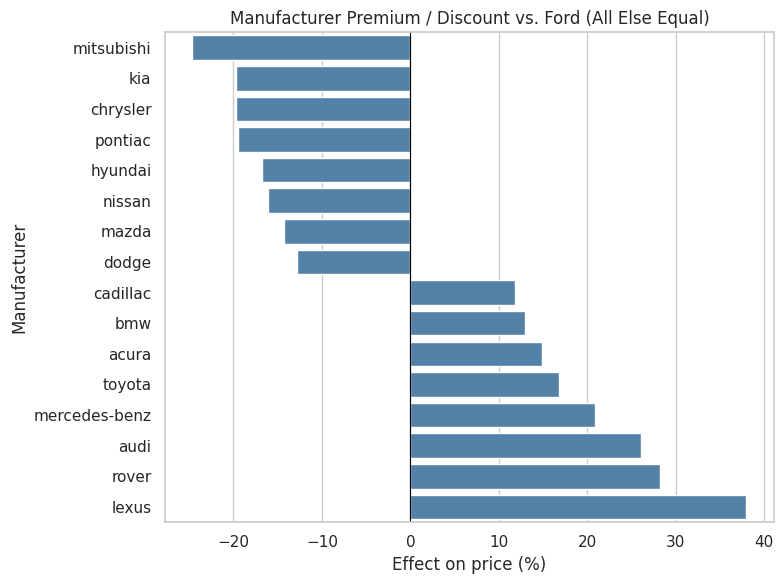

% price effect vs. reference
group        level                                      
condition    excellent                              10.5
             fair                                  -40.4
             salvage                               -41.8
title_status rebuilt                               -22.7
             salvage                               -29.2
type         truck                                  36.3
             pickup                                 34.2
             SUV                                    13.3
             hatchback                              -3.4
drive        4wd                                    29.6
             rwd                                    24.1
cylinders    8 cylinders                            23.0
             4 cylinders                           -17.9
fuel         diesel                                101.2
             hybrid                                 -2.9
             electric                              -11.5
transmission manual                                 14.9
manufacturer lexus                                  38.0
             audi                                   26.0
             mercedes-benz                          20.9
             toyota                                 16.9
             mitsubishi                            -24.6
             kia                                   -19.8
             chrysler                              -19.7

In [18]:
# Manufacturer effects (vs. Ford), the 8 strongest premiums and discounts among brands with 1,000+ listings
brand_counts = X_train['manufacturer'].value_counts()
brands = cat[(cat['group'] == 'manufacturer') & cat['level'].isin(brand_counts[brand_counts >= 1_000].index)]
brands = pd.concat([brands.nlargest(8, 'pct_effect'), brands.nsmallest(8, 'pct_effect')]).sort_values('pct_effect')

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=brands, x='pct_effect', y='level', color='steelblue', ax=ax)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Manufacturer Premium / Discount vs. Ford (All Else Equal)')
ax.set_xlabel('Effect on price (%)')
ax.set_ylabel('Manufacturer')
plt.tight_layout()
plt.show()

# Key effects in one table (these are the numbers quoted in the findings)
key_levels = [('condition', 'excellent'), ('condition', 'fair'), ('condition', 'salvage'),
              ('title_status', 'rebuilt'), ('title_status', 'salvage'),
              ('type', 'truck'), ('type', 'pickup'), ('type', 'SUV'), ('type', 'hatchback'),
              ('drive', '4wd'), ('drive', 'rwd'), ('cylinders', '8 cylinders'), ('cylinders', '4 cylinders'),
              ('fuel', 'diesel'), ('fuel', 'hybrid'), ('fuel', 'electric'), ('transmission', 'manual'),
              ('manufacturer', 'lexus'), ('manufacturer', 'audi'), ('manufacturer', 'mercedes-benz'),
              ('manufacturer', 'toyota'), ('manufacturer', 'mitsubishi'), ('manufacturer', 'kia'),
              ('manufacturer', 'chrysler')]
key_effects = (cat.set_index(['group', 'level']).loc[key_levels, ['pct_effect']]
               .round(1).rename(columns={'pct_effect': '% price effect vs. reference'}))
key_effects

### Caveats about the interpretation

- **Association, not causation.** For instance, diesel's very large premium partly reflects that more than half of diesel listings are pickups and trucks, and a linear model only partly separates fuel from body type and cylinders.
- **Asking prices** from listings are likely higher than final sale prices.
- Roughly 40% of listings did not report `condition`, so the `unknown` condition group is a mix of everything and is not a quality grade. `new` also comes out slightly below `excellent`, which reflects how few `new` listings there are and how sellers use the label.
- The model explains a large share of price variation, but individual cars can still be off by a lot (see the error-by-price-band table), so it is a guide for *what to stock*, not an appraisal tool.

## 7. Findings and Recommendations (Deployment)

*Written for used car dealers. Percentages come from a model that predicts price from vehicle attributes (it explains about 78% of the variation in price). Each effect is "all else equal" and compared with a common reference car, so they are not simply differences in average price.*

### How much can we explain?
The model's price estimate is typically within about **\$4,700** of the asking price (median error about **20%**). It is most accurate for mainstream cars between \$10k and \$40k, and much less precise for very cheap cars (under \$5k, where small dollar gaps are large percentages) and for expensive cars (over \$40k). Use it as a guide to **what to stock**, not as an appraisal tool.

### What buyers pay for (largest effects)

| Driver | What the data say |
|---|---|
| **Age** | Each extra year of age lowers price by about **7%**, even for cars with the same mileage. |
| **Mileage** | Each extra 10,000 miles lowers price by about **4%** on top of the age effect. A car that is 5 years older *and* has 50,000 more miles is expected to sell for roughly **43% less**. |
| **Condition and title** | Cars reported as *fair* or *salvage* sell about **40% lower** than *good* cars; *excellent* earns about **10% more**. A *salvage* title costs about **29%** and a *rebuilt* title about **23%** compared with a clean title. |
| **Body type** | Compared with a sedan: **trucks +36%**, **pickups +34%**, **SUVs +13%**. Hatchbacks are about level with sedans. |
| **Drivetrain and engine** | **4WD +30%** and **RWD +24%** compared with front-wheel drive. **8-cylinder +23%**, while **4-cylinder is about 18% lower** than 6-cylinder. |
| **Brand** | Compared with Ford: **Lexus +38%**, **Audi +26%**, **Mercedes-Benz +21%**, **Toyota +17%**. Discounts: **Mitsubishi −25%**, **Kia −20%**, **Chrysler −20%**. |
| **Fuel** | **Diesel about +100%** (largely heavy-duty trucks). **Hybrid is about level (−3%) and electric about 12% lower** than gas once age, mileage and body type are accounted for. |
| **Transmission** | Raw average prices for manuals are *lower* (manuals tend to be older cars), but compared with an automatic of the same age, mileage, body type and so on, **manual is about 15% higher**. There is no evidence of an automatic premium. |

### Recommendations for inventory
1. **Buy on age and mileage first.** They are the two strongest drivers, and the effects compound. Within a model year, prefer the lower-mileage examples, since every 10,000 miles is worth about 4%.
2. **Avoid salvage, rebuilt and "fair" cars unless the purchase discount covers the markdown** (roughly 20–40%). Buyers heavily discount them.
3. **Lean toward trucks, pickups, SUVs and 4WD vehicles**, which consistently command the biggest premiums. Cars with 4-cylinder engines and compact sedans carry the lowest prices.
4. **Favor Toyota, Lexus, Audi and Mercedes-Benz for premium resale value.** Expect lower prices for Mitsubishi, Kia and Chrysler.
5. **Do not pay extra for hybrids or electric vehicles** on the basis of this data. They do not command a premium here, once they are compared with similar age, mileage and body type.
6. **Do not assume automatics carry a premium.** Manuals are priced somewhat higher (likely a niche, enthusiast segment), but the manual market is small.
7. **Document condition on every listing.** About 41% of listings omit it, and complete, clean listings are easier for buyers to price.

### Limitations
- These are **asking prices** from online listings, not sale prices, and the dataset has no information on **how fast cars sold** or **dealer margin**. A higher price is not automatically a higher profit.
- The model finds **associations**, not causes. Effects such as diesel are mixed with body type and engine size.
- Listings priced below \$1,000 or above \$100,000, models before 1995, and about a quarter of all rows were removed during cleaning (see Section 3).
- `model` and `region` were not used, so model-level (e.g. Camry vs Corolla) and regional differences are not captured.

### Next steps
1. Add **sold-price and days-to-sell data** so recommendations can optimize for turnover and margin, not just price.
2. Add **model-level** information (for example grouping the 30,000 model names into a few hundred) and **region**, to capture local demand.
3. Test **non-linear models** (for example gradient-boosted trees) to see whether they predict better, then compare their feature importances with these coefficients.
4. Refit the model **regularly on new listings** to track market shifts, such as used-EV prices and seasonal effects.